# 21 · Contacts: friction cones, solref / solimp, condim, contact forces

In [1]:
import mujoco, numpy as np, matplotlib.pyplot as plt

def incline(angle_deg, mu, condim=3):
    xml = f"""<mujoco><option timestep="0.002" cone="elliptic"/>
    <worldbody><light pos="0 0 3"/>
      <geom name="ramp" type="box" size="1 .3 .02" euler="0 {-angle_deg} 0" friction="{mu} .005 .0001" condim="{condim}"/>
      <body name="box" pos="0 0 .07" euler="0 {-angle_deg} 0"><freejoint/>
        <geom type="box" size=".05 .05 .05" mass="1" friction="{mu} .005 .0001" condim="{condim}"/></body>
    </worldbody></mujoco>"""
    m = mujoco.MjModel.from_xml_string(xml)
    return m, mujoco.MjData(m)

def drop(timeconst, dampratio=1.0, solimp=(0.9, 0.95, 0.001, 0.5, 2), mass=1.0, T=1.5):
    xml = f"""<mujoco><option timestep="0.001"/>
    <worldbody><geom type="plane" size="1 1 .1" solref="{timeconst} {dampratio}" solimp="{' '.join(map(str, solimp))}"/>
      <body pos="0 0 .3"><freejoint/><geom type="sphere" size=".05" mass="{mass}" solref="{timeconst} {dampratio}" solimp="{' '.join(map(str, solimp))}"/></body>
    </worldbody></mujoco>"""
    m = mujoco.MjModel.from_xml_string(xml); d = mujoco.MjData(m)
    zs = []
    while d.time < T:
        mujoco.mj_step(m, d); zs.append(d.qpos[2])
    return np.array(zs)

def rolling(condim):
    xml = f"""<mujoco><option timestep="0.002" cone="elliptic"/>
    <worldbody><geom type="plane" size="3 3 .1" condim="{condim}" friction="1 .005 .02"/>
      <body pos="0 0 .1"><freejoint/><geom type="sphere" size=".1" mass="1" condim="{condim}" friction="1 .005 .02"/></body>
    </worldbody></mujoco>"""
    m = mujoco.MjModel.from_xml_string(xml); d = mujoco.MjData(m)
    d.qvel[0] = 1.0; d.qvel[4] = 10.0
    xs = []
    while d.time < 3:
        mujoco.mj_step(m, d); xs.append(d.qpos[0])
    return np.array(xs)

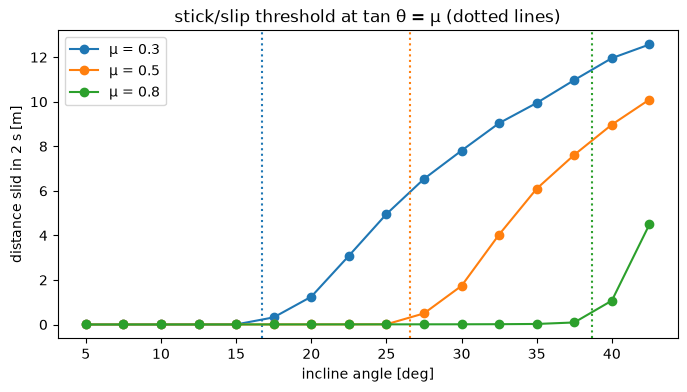

In [2]:
angles = np.arange(5, 45, 2.5)
mus = [0.3, 0.5, 0.8]
plt.figure(figsize=(8, 4))
for mu in mus:
    slid = []
    for a in angles:
        m, d = incline(a, mu)
        x0 = d.qpos[:3].copy()
        mujoco.mj_step(m, d, 1000)
        slid.append(np.linalg.norm(d.qpos[:3] - x0))
    plt.plot(angles, slid, "o-", label=f"μ = {mu}")
    plt.axvline(np.degrees(np.arctan(mu)), ls=":", c=plt.gca().lines[-1].get_color())
plt.xlabel("incline angle [deg]"); plt.ylabel("distance slid in 2 s [m]"); plt.legend()
plt.title("stick/slip threshold at tan θ = μ (dotted lines)"); plt.show()

In [3]:
m, d = incline(15, 0.8)
mujoco.mj_step(m, d, 500)
f6 = np.zeros(6)
total = np.zeros(3)
for i in range(d.ncon):
    mujoco.mj_contactForce(m, d, i, f6)
    frame = d.contact[i].frame.reshape(3, 3)
    total += frame.T @ f6[:3]
print(f"{d.ncon} contacts | total contact force in world frame: {total.round(3)} N | weight = {9.81:.2f} N")

4 contacts | total contact force in world frame: [0.   0.   9.81] N | weight = 9.81 N


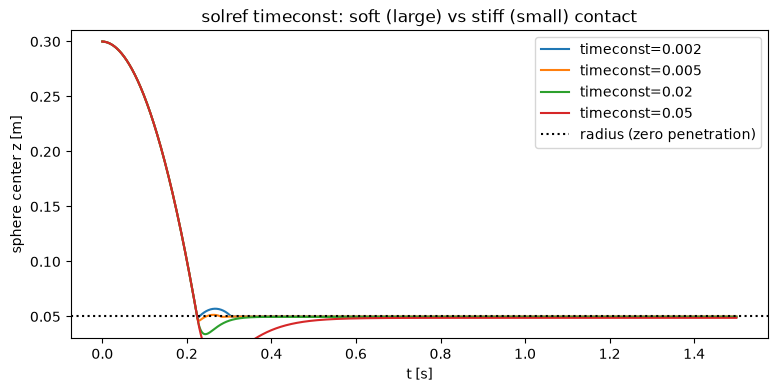

In [4]:
plt.figure(figsize=(9, 4))
for tc in [0.002, 0.005, 0.02, 0.05]:
    z = drop(tc)
    plt.plot(np.arange(len(z)) * 1e-3, z, label=f"timeconst={tc}")
plt.axhline(0.05, c="k", ls=":", label="radius (zero penetration)")
plt.ylim(0.03, 0.31); plt.xlabel("t [s]"); plt.ylabel("sphere center z [m]"); plt.legend()
plt.title("solref timeconst: soft (large) vs stiff (small) contact"); plt.show()

In [5]:
for tc in [0.002, 0.02]:
    for mass in [0.1, 1.0, 10.0]:
        z = drop(tc, mass=mass)
        print(f"timeconst={tc:<6} mass={mass:<5} steady penetration = {(0.05 - z[-1]) * 1000:.3f} mm")

timeconst=0.002  mass=0.1   steady penetration = 0.004 mm
timeconst=0.002  mass=1.0   steady penetration = 0.004 mm
timeconst=0.002  mass=10.0  steady penetration = 0.004 mm
timeconst=0.02   mass=0.1   steady penetration = 0.367 mm
timeconst=0.02   mass=1.0   steady penetration = 0.367 mm
timeconst=0.02   mass=10.0  steady penetration = 0.367 mm


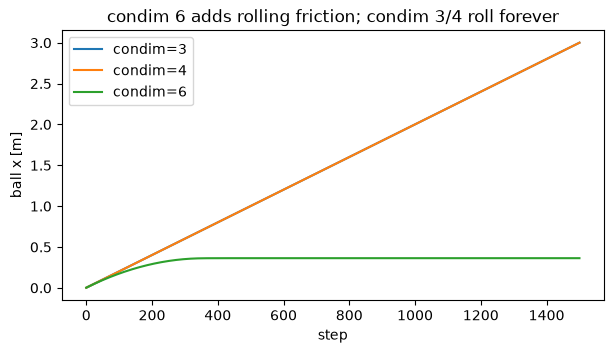

In [6]:
plt.figure(figsize=(7, 3.5))
for c in [3, 4, 6]:
    plt.plot(rolling(c), label=f"condim={c}")
plt.xlabel("step"); plt.ylabel("ball x [m]"); plt.legend()
plt.title("condim 6 adds rolling friction; condim 3/4 roll forever"); plt.show()